# 4. Connectivity and Graph Properties
**Question:** How connected are the airports, and what do graph distances mean?

We build the airport graph from `routes.dat`, then look at components, shortest paths, diameter and clustering, and finish with a properties table. Distance here always means route hops, and section 4 shows why that is not travel time.

**Terms used below**
- *Walk*: any chain of routes. *Path*: a walk that does not visit an airport twice. *Shortest path*: the path with the fewest routes.
- *Connected component*: a set of airports that can all reach each other.
- *Diameter*: the largest shortest-path length in the graph. *Average path length*: mean hops over all airport pairs.
- *Triangle*: three airports that are all directly linked. *Local clustering*: the share of an airport's neighbour pairs that are also linked.

In [1]:
import numpy as np, pandas as pd, networkx as nx
import matplotlib.pyplot as plt
from collections import Counter
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
DATA = "../data/"

## 1. Build the graph
Assumptions: a node is an airport (IATA code). An edge means at least one route exists between two airports in either direction. Many airlines flying the same pair collapse into one edge. Self-loops and rows with a missing (`\N`) code are dropped. We ignore direction because we care about structure, not which way a flight goes (99.6% of routes are bidirectional anyway).

In [2]:
cols = ["airline","airline_id","src","src_id","dst","dst_id","codeshare","stops","equipment"]
routes = pd.read_csv(DATA+"routes.dat", header=None, names=cols, na_values=["\\N"], keep_default_na=False)
acols = ["id","name","city","country","iata","icao","lat","lon","alt","tz","dst","tzdb","type","source"]
airports = pd.read_csv(DATA+"airports.dat", header=None, names=acols, na_values=["\\N"], keep_default_na=False)
airports = airports.dropna(subset=["iata"]).drop_duplicates("iata").set_index("iata")

r = routes.dropna(subset=["src","dst"])
r = r[r.src != r.dst]
edges = {tuple(sorted(e)) for e in zip(r.src, r.dst)}
G = nx.Graph(edges)
print(f"route rows: {len(routes):,} | usable: {len(r):,}")
print(f"nodes: {G.number_of_nodes():,} | edges (unique undirected): {G.number_of_edges():,}")
assert nx.number_of_selfloops(G) == 0
print("airports with coordinates:", sum(n in airports.index for n in G), "/", G.number_of_nodes())

route rows: 67,663 | usable: 67,662
nodes: 3,425 | edges (unique undirected): 19,256
airports with coordinates: 3262 / 3425


## 2. Connected components
First question: can every airport reach every other one? If not, the graph has separate islands, and we count them.

In [3]:
comps = sorted(nx.connected_components(G), key=len, reverse=True)
sizes = [len(c) for c in comps]
assert sum(sizes) == G.number_of_nodes()
giant = G.subgraph(comps[0]).copy()
print(f"components: {len(comps)} | giant component: {sizes[0]:,} airports "
      f"({sizes[0]/G.number_of_nodes():.1%}) | is connected overall: {nx.is_connected(G)}")
print("next largest sizes:", sizes[1:11])
print("components of size <= 3:", sum(s <= 3 for s in sizes))
for c in comps[1:4]:
    print(sorted(c)[:6], [airports.country.get(a, "?") for a in sorted(c)[:3]])

components: 8 | giant component: 3,397 airports (99.2%) | is connected overall: False
next largest sizes: [10, 4, 4, 4, 2, 2, 2]
components of size <= 3: 3
['BMY', 'GEA', 'ILP', 'KNQ', 'KOC', 'LIF'] ['New Caledonia', 'New Caledonia', 'New Caledonia']
['ERS', 'MPA', 'NDU', 'OND'] ['Namibia', 'Namibia', 'Namibia']
['BFI', 'CLM', 'ESD', 'FRD'] ['United States', 'United States', 'United States']


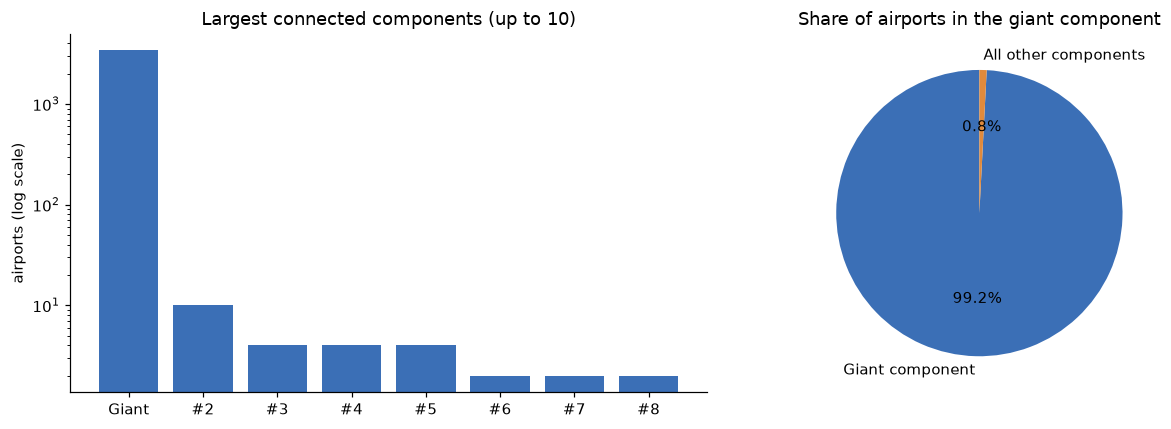

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
top = sizes[:10]; ax[0].bar(["Giant"] + [f"#{i}" for i in range(2, len(top)+1)], top, color="#3b6fb6")
ax[0].set_yscale("log"); ax[0].set_ylabel("airports (log scale)"); ax[0].set_title("Largest connected components (up to 10)")
ax[1].pie([sizes[0], G.number_of_nodes()-sizes[0]], labels=["Giant component","All other components"],
          autopct="%1.1f%%", colors=["#3b6fb6","#e08a3c"], startangle=90)
ax[1].set_title("Share of airports in the giant component")
plt.tight_layout(); plt.show()

### The islands up close
All seven non-giant components, drawn with a spring layout and one colour each.

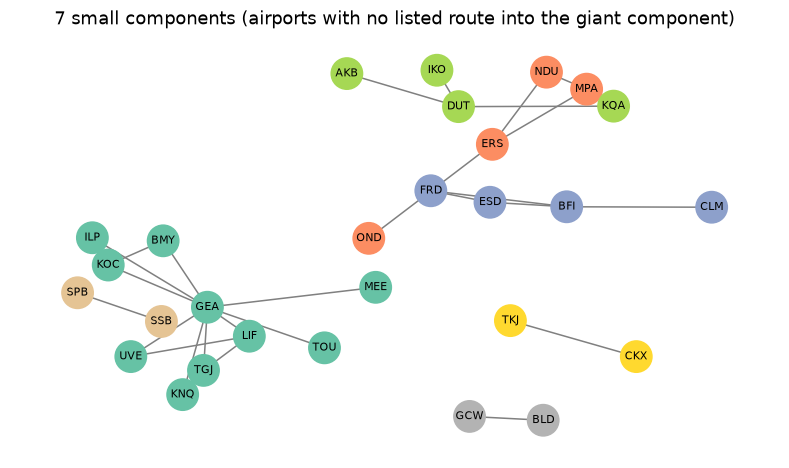

In [5]:
small = nx.compose_all([G.subgraph(c) for c in comps[1:]])
colors = {n: i for i, c in enumerate(comps[1:]) for n in c}
fig, ax = plt.subplots(figsize=(9, 5))
p = nx.spring_layout(small, seed=1, k=0.6)
nx.draw_networkx(small, p, ax=ax, node_color=[colors[n] for n in small], cmap=plt.cm.Set2,
                 node_size=420, font_size=7, edge_color="gray", with_labels=True)
ax.set_title(f"{len(comps)-1} small components (airports with no listed route into the giant component)"); ax.axis("off")
plt.show()

## 3. Shortest paths, average path length, diameter
Distance is undefined between components, so from here on we use the giant component only. It has about 3,400 airports, so we run BFS from every airport and get exact values with no sampling.

### Walk vs path vs shortest path
A small example first. A walk can repeat airports, a path cannot, and the shortest path uses the fewest edges.

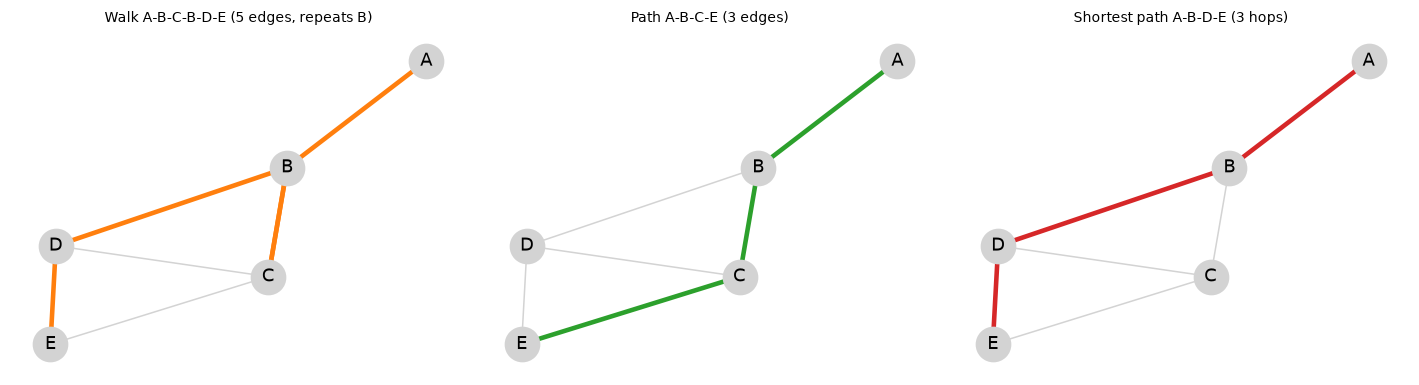

In [6]:
W = nx.Graph([("A","B"),("B","C"),("C","D"),("B","D"),("D","E"),("C","E")])
pos = nx.spring_layout(W, seed=3)
walk = ["A","B","C","B","D","E"]          # revisits B
path = ["A","B","C","E"]                  # no repeats, but longer than needed
short = nx.shortest_path(W, "A", "E")     # fewest hops
assert len(set(path)) == len(path) and len(set(walk)) < len(walk) and len(short) - 1 == 3 == nx.shortest_path_length(W, "A", "E")
fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
for a, seq, ttl, col in zip(axs, [walk, path, short], ["Walk A-B-C-B-D-E (5 edges, repeats B)", "Path A-B-C-E (3 edges)", f"Shortest path {'-'.join(short)} ({len(short)-1} hops)"], ["tab:orange","tab:green","tab:red"]):
    nx.draw_networkx_nodes(W, pos, ax=a, node_color="lightgray", node_size=500)
    nx.draw_networkx_edges(W, pos, ax=a, edge_color="lightgray")
    nx.draw_networkx_edges(W, pos, ax=a, edgelist=list(zip(seq, seq[1:])), edge_color=col, width=3, arrows=False)
    nx.draw_networkx_labels(W, pos, ax=a); a.set_title(ttl, fontsize=9); a.axis("off")
plt.tight_layout(); plt.show()

In [7]:
# exact all-pairs hop distances on the giant component
dist = dict(nx.all_pairs_shortest_path_length(giant))
n = giant.number_of_nodes()
pair_d = np.array([d for s in dist.values() for d in s.values() if d > 0])   # ordered pairs, s != t
ecc = {s: max(v.values()) for s, v in dist.items()}
diameter, radius = max(ecc.values()), min(ecc.values())
avg_len = pair_d.mean()
# check against networkx built-ins
assert diameter == nx.diameter(giant, e=ecc) and abs(avg_len - nx.average_shortest_path_length(giant)) < 1e-9
print(f"giant component: {n:,} nodes, {giant.number_of_edges():,} edges")
print(f"average path length: {avg_len:.2f} hops | diameter: {diameter} hops | radius: {radius} hops")
print("share of pairs reachable in <=3 hops: %.1f%%" % (100*(pair_d <= 3).mean()))

giant component: 3,397 nodes, 19,230 edges
average path length: 4.10 hops | diameter: 13 hops | radius: 7 hops
share of pairs reachable in <=3 hops: 32.5%


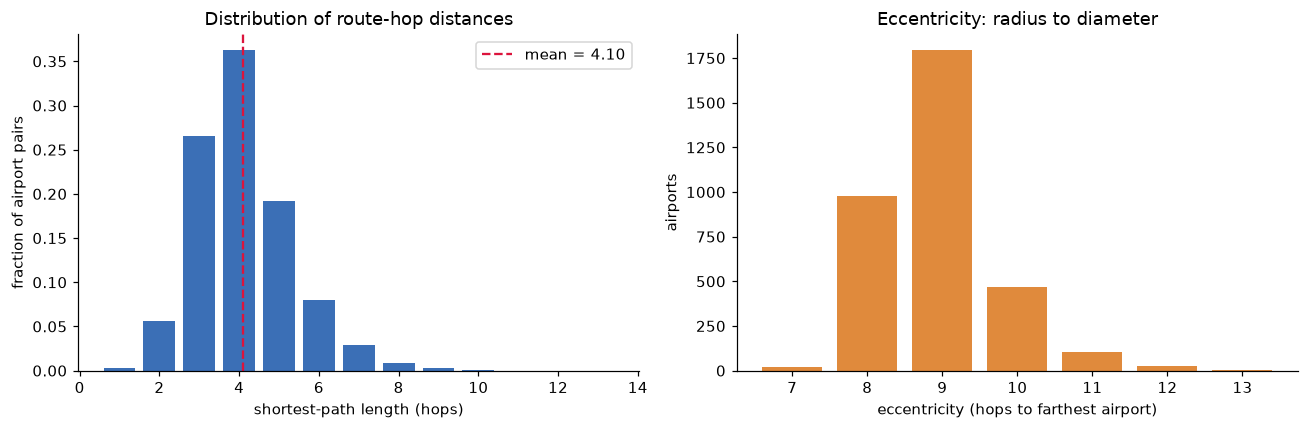

In [8]:
counts = Counter(pair_d); xs = sorted(counts)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(xs, [counts[x]/len(pair_d) for x in xs], color="#3b6fb6")
ax[0].axvline(avg_len, color="crimson", ls="--", label=f"mean = {avg_len:.2f}")
ax[0].set(xlabel="shortest-path length (hops)", ylabel="fraction of airport pairs", title="Distribution of route-hop distances")
ax[0].legend()
ec = Counter(ecc.values()); ks = sorted(ec)
ax[1].bar(ks, [ec[k] for k in ks], color="#e08a3c")
ax[1].set(xlabel="eccentricity (hops to farthest airport)", ylabel="airports", title="Eccentricity: radius to diameter")
plt.tight_layout(); plt.show()

### One longest shortest path
We pick an airport pair at distance 13 and draw its route.

13-hop path: QUV (?, ?) -> XEQ (?, ?) -> JNN (Nanortalik, Greenland) -> JJU (Qaqortoq, Greenland) -> UAK (Narssarssuaq, Greenland) -> SFJ (Sondrestrom, Greenland) -> CPH (Copenhagen, Denmark) -> DOH (Doha, Qatar) -> YUL (Montreal, Canada) -> YVP (Quujjuaq, Canada) -> YKG (Kangirsuk, Canada) -> YQC (Quaqtaq, Canada) -> YWB (Kangiqsujuaq, Canada) -> YZG (Salluit, Canada)


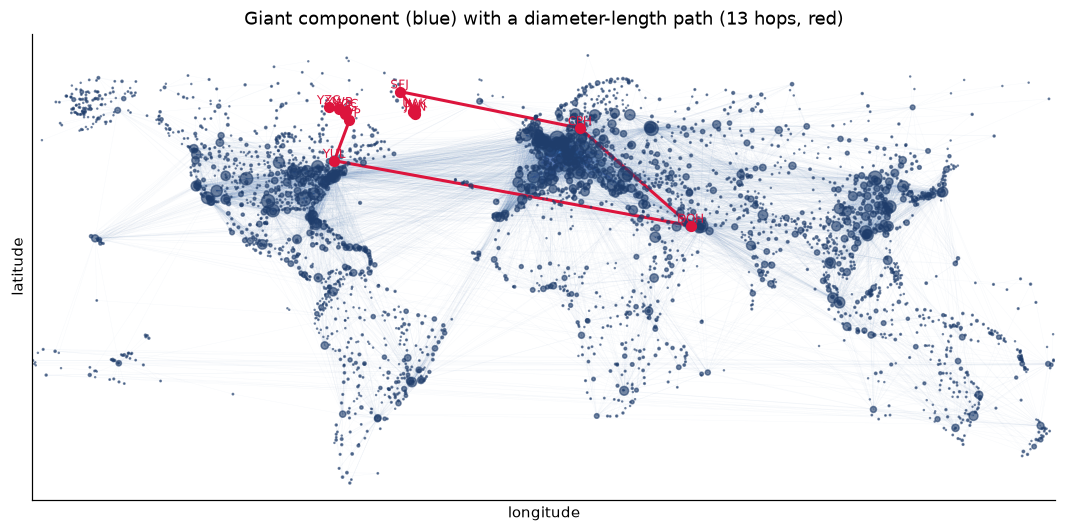

In [9]:
src = next(s for s, e in ecc.items() if e == diameter)
dst = next(t for t, d in dist[src].items() if d == diameter)
path = nx.shortest_path(giant, src, dst)
nm = lambda a: f"{a} ({airports.city.get(a, '?')}, {airports.country.get(a, '?')})"
print(f"{diameter}-hop path:", " -> ".join(nm(a) for a in path))

pos = {a: (airports.lon[a], airports.lat[a]) for a in giant if a in airports.index}
def draw_map(ax, graph, highlight=None):
    g = graph.subgraph(pos)                                   # airports with coordinates
    nx.draw_networkx_edges(g, pos, ax=ax, width=0.3, alpha=0.04, edge_color="#3b6fb6")
    nx.draw_networkx_nodes(g, pos, ax=ax, node_size=[g.degree(n)*0.4 for n in g], node_color="#1f3d6b", alpha=0.6)
    if highlight:
        hp = [a for a in highlight if a in pos]
        nx.draw_networkx_edges(g, pos, ax=ax, edgelist=list(zip(hp, hp[1:])), width=2, edge_color="crimson")
        nx.draw_networkx_nodes(g, pos, ax=ax, nodelist=hp, node_size=40, node_color="crimson")
        nx.draw_networkx_labels(g.subgraph(hp), pos, ax=ax, font_size=8, font_color="crimson", verticalalignment="bottom")
    ax.set(xlim=(-180, 180), ylim=(-60, 85), xlabel="longitude", ylabel="latitude")
    ax.axis("on")

fig, ax = plt.subplots(figsize=(12, 5.5))
draw_map(ax, giant, path); ax.set_title(f"Giant component (blue) with a diameter-length path ({diameter} hops, red)")
plt.show()

## 4. Distance is route hops, not travel time
An edge has no length unless we give it one, and ours only counts routes. To test whether hops say anything about distance, we compare hops with great-circle kilometres for 4,000 random airport pairs.

In [10]:
def haversine(a, b):
    la1, lo1, la2, lo2 = map(np.radians, [airports.lat[a], airports.lon[a], airports.lat[b], airports.lon[b]])
    h = np.sin((la2-la1)/2)**2 + np.cos(la1)*np.cos(la2)*np.sin((lo2-lo1)/2)**2
    return 2*6371*np.arcsin(np.sqrt(h))

rng = np.random.default_rng(0)
nodes = [a for a in giant if a in airports.index]
pairs = [tuple(rng.choice(nodes, 2, replace=False)) for _ in range(4000)]
dd = pd.DataFrame({"hops": [dist[a][b] for a, b in pairs], "km": [haversine(a, b) for a, b in pairs]})
print("correlation hops vs km: %.2f" % dd.hops.corr(dd.km))
print(dd.groupby("hops").km.agg(["count", "median", "max"]).round(0))
# a 1-hop pair that is physically far, a 3+ hop pair that is physically close
far1 = max(((a, b) for a, b in giant.edges() if a in airports.index and b in airports.index), key=lambda e: haversine(*e))
print("\nlongest single hop:", far1, f"{haversine(*far1):,.0f} km")
close = dd[(dd.hops >= 3)].nsmallest(1, "km").index[0]; a, b = pairs[close]
print(f"close but many hops: {a}-{b}: {dd.hops[close]} hops, {dd.km[close]:,.0f} km")

correlation hops vs km: 0.34
      count   median      max
hops                         
1        19    939.0  11774.0
2       254   2562.0  14633.0
3      1116   6884.0  19944.0
4      1534   9414.0  19173.0
5       718   9955.0  19738.0
6       255   9794.0  19391.0
7        81   9110.0  18338.0
8        18  10181.0  17639.0
9         3  11588.0  15784.0
10        2   7796.0  11125.0

longest single hop: ('SYD', 'DFW') 13,808 km
close but many hops: XFW-SGD: 4 hops, 159 km


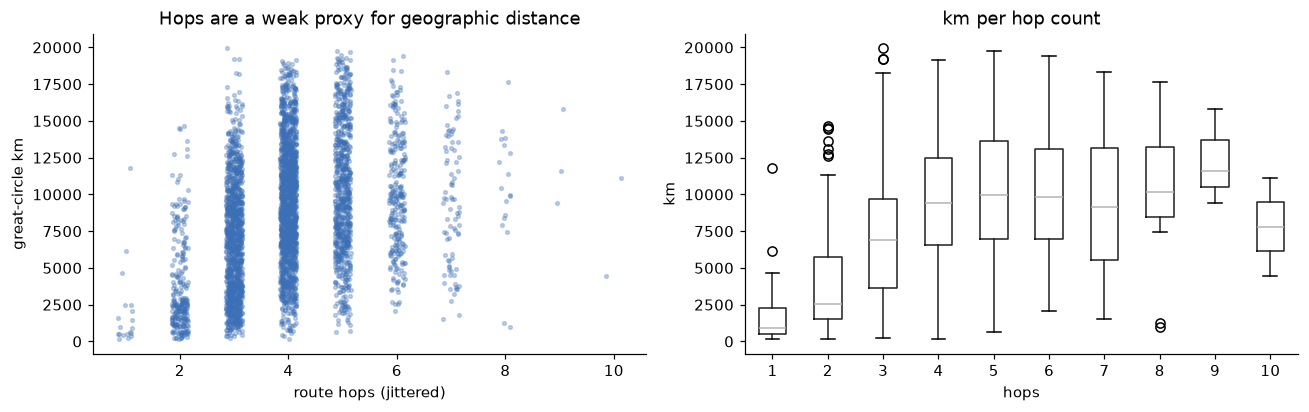

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
jit = dd.hops + rng.uniform(-0.15, 0.15, len(dd))
ax[0].scatter(jit, dd.km, s=6, alpha=0.3, color="#3b6fb6")
ax[0].set(xlabel="route hops (jittered)", ylabel="great-circle km", title="Hops are a weak proxy for geographic distance")
dd.boxplot(column="km", by="hops", ax=ax[1], grid=False); ax[1].set(title="km per hop count", xlabel="hops", ylabel="km")
plt.suptitle(""); plt.tight_layout(); plt.show()

## 5. Triangles and clustering
A triangle is three airports that are all linked to each other. An airport has high clustering when its neighbours tend to be linked too. To see whether our value is more than chance, we compare it with a random graph with the same number of nodes and edges (Erdős–Rényi).

In [12]:
tri = nx.triangles(G)
n_triangles = sum(tri.values()) // 3
cc = nx.clustering(G)
avg_cc, trans = nx.average_clustering(G), nx.transitivity(G)
rand = nx.gnm_random_graph(G.number_of_nodes(), G.number_of_edges(), seed=0)
print(f"triangles: {n_triangles:,}")
print(f"average local clustering: {avg_cc:.3f} | global clustering (transitivity): {trans:.3f}")
print(f"random graph same size  : avg {nx.average_clustering(rand):.3f}, transitivity {nx.transitivity(rand):.3f}")
# tiny worked example of the definition
H = nx.Graph([("A","B"),("A","C"),("A","D"),("B","C")])
print("toy: clustering of A =", nx.clustering(H, "A"), "(1 of 3 neighbour pairs linked)")
assert nx.clustering(H, "A") == 1/3

triangles: 101,117
average local clustering: 0.487 | global clustering (transitivity): 0.248
random graph same size  : avg 0.003, transitivity 0.004
toy: clustering of A = 0.3333333333333333 (1 of 3 neighbour pairs linked)


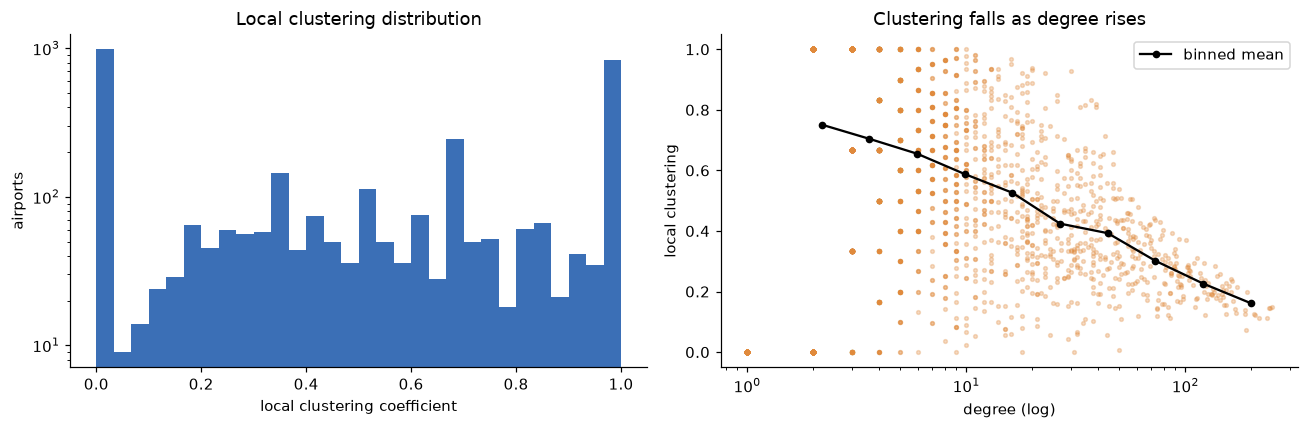

top triangle airports: [('AMS', 4543), ('FRA', 4357), ('CDG', 4136), ('MUC', 3658), ('LHR', 3168)]


In [13]:
deg = dict(G.degree())
df = pd.DataFrame({"deg": pd.Series(deg), "cc": pd.Series(cc)})
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(df.cc, bins=30, color="#3b6fb6"); ax[0].set(xlabel="local clustering coefficient", ylabel="airports", yscale="log", title="Local clustering distribution")
ax[1].scatter(df.deg, df.cc, s=6, alpha=0.3, color="#e08a3c"); ax[1].set_xscale("log")
bins = df[df.deg>1].groupby(pd.cut(df.deg[df.deg>1], np.logspace(0, np.log10(df.deg.max()), 12)), observed=True).cc.mean()
ax[1].plot([iv.mid for iv in bins.index], bins.values, "k-o", ms=4, label="binned mean"); ax[1].legend()
ax[1].set(xlabel="degree (log)", ylabel="local clustering", title="Clustering falls as degree rises")
plt.tight_layout(); plt.show()
print("top triangle airports:", sorted(tri.items(), key=lambda x: -x[1])[:5])

### Clustering illustrated
Left: a toy graph where A has 3 neighbours and only one pair of them is linked, so clustering is 1/3. Middle and right: the real neighbourhood of a small airport and of the biggest hub.

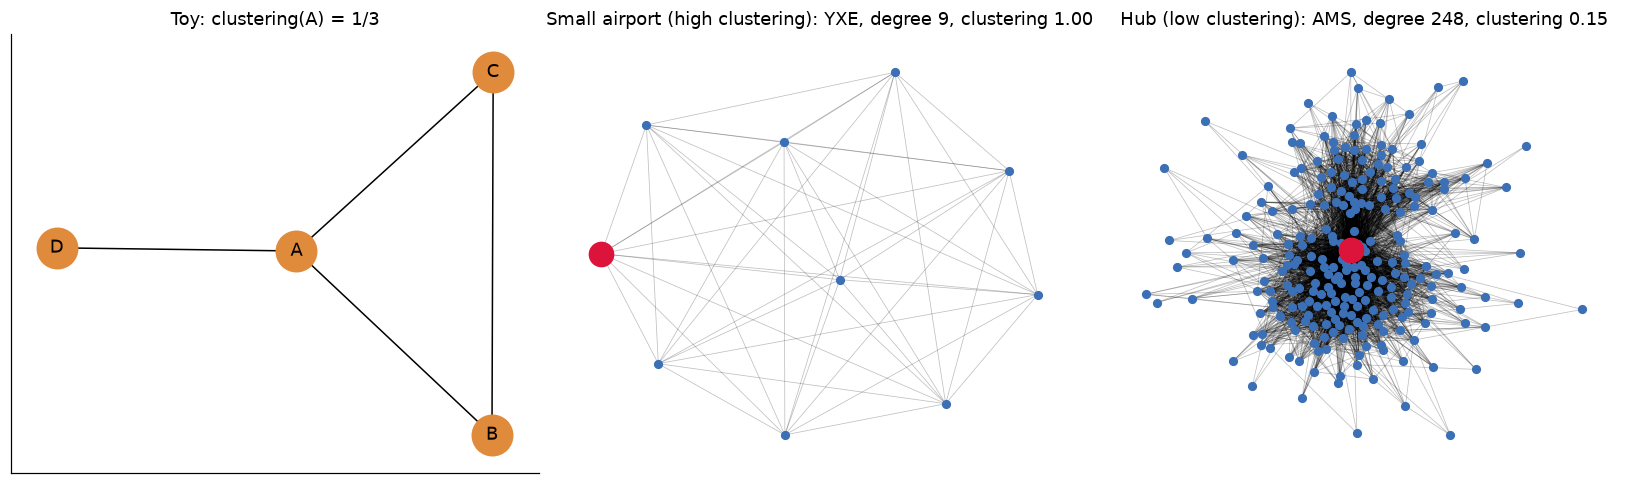

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
tp = nx.spring_layout(H, seed=2)
nx.draw_networkx(H, tp, ax=ax[0], node_color="#e08a3c", node_size=700, with_labels=True)
ax[0].set_title("Toy: clustering(A) = 1/3")
def ego(a, axis, title):
    E = nx.ego_graph(G, a); q = nx.spring_layout(E, seed=3, k=0.4)
    others = [n for n in E if n != a]
    nx.draw_networkx_edges(E, q, ax=axis, alpha=0.25, width=0.5)
    nx.draw_networkx_nodes(E, q, nodelist=others, ax=axis, node_size=25, node_color="#3b6fb6")
    nx.draw_networkx_nodes(E, q, nodelist=[a], ax=axis, node_size=250, node_color="crimson")
    axis.set_title(f"{title}: {a}, degree {G.degree(a)}, clustering {cc[a]:.2f}"); axis.axis("off")
hub = max(G.degree, key=lambda x: x[1])[0]
mid = min((n for n in G if 8 <= G.degree(n) <= 12), key=lambda n: -cc[n])
ego(mid, ax[1], "Small airport (high clustering)"); ego(hub, ax[2], "Hub (low clustering)")
plt.tight_layout(); plt.show()

### Real network vs random graph
A random graph with the same 3,425 nodes and 19,256 edges, with edges placed at random.

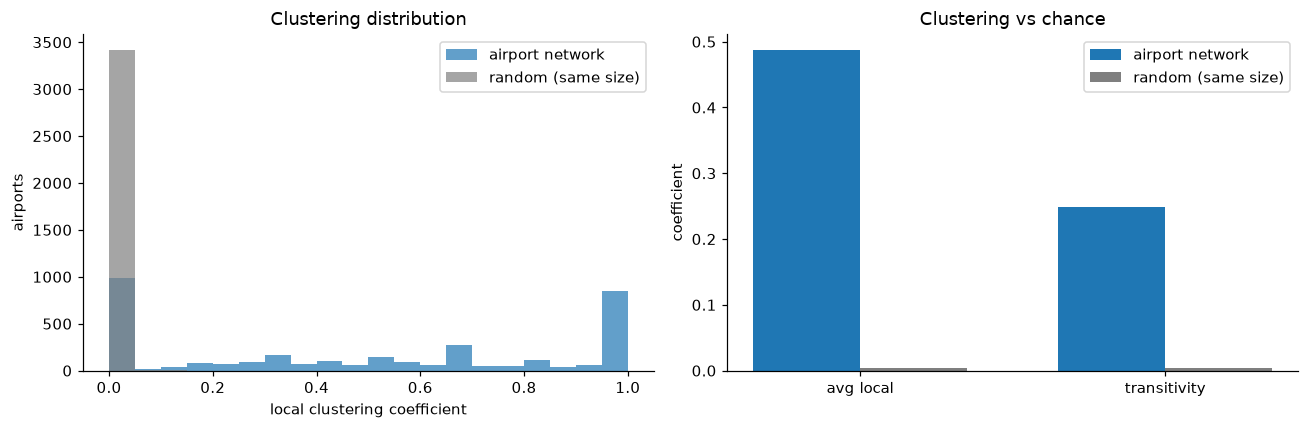

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
rcc = nx.clustering(rand)
bins = np.linspace(0, 1, 21)
ax[0].hist(list(cc.values()), bins=bins, alpha=.7, label="airport network", color="tab:blue")
ax[0].hist(list(rcc.values()), bins=bins, alpha=.7, label="random (same size)", color="tab:gray")
ax[0].set(xlabel="local clustering coefficient", ylabel="airports", title="Clustering distribution"); ax[0].legend()
vals = {"avg local": (avg_cc, nx.average_clustering(rand)), "transitivity": (trans, nx.transitivity(rand))}
x = np.arange(len(vals)); w = .35
ax[1].bar(x - w/2, [v[0] for v in vals.values()], w, label="airport network", color="tab:blue")
ax[1].bar(x + w/2, [v[1] for v in vals.values()], w, label="random (same size)", color="tab:gray")
ax[1].set_xticks(x, list(vals)); ax[1].set(ylabel="coefficient", title="Clustering vs chance"); ax[1].legend()
plt.tight_layout(); plt.show()

## 6. Properties summary
Values from the cells above, on the full graph unless marked giant.

In [16]:
summary = pd.Series({
    "Airports (nodes)": G.number_of_nodes(),
    "Unique undirected routes (edges)": G.number_of_edges(),
    "Density": round(nx.density(G), 4),
    "Connected components": len(comps),
    "Giant component size (share)": f"{sizes[0]:,} ({sizes[0]/G.number_of_nodes():.1%})",
    "Average path length (hops, giant)": round(avg_len, 2),
    "Diameter / radius (hops, giant)": f"{diameter} / {radius}",
    "Triangles": n_triangles,
    "Average local clustering": round(avg_cc, 3),
    "Transitivity": round(trans, 3),
    "Random-graph clustering (same size)": round(nx.average_clustering(rand), 4),
}, name="value").to_frame()
summary

,value
Airports (nodes),3425
Unique undirected routes (edges),19256
Density,0.0033
Connected components,8
Giant component size (share),"3,397 (99.2%)"
"Average path length (hops, giant)",4.1
"Diameter / radius (hops, giant)",13 / 7
Triangles,101117
Average local clustering,0.487
Transitivity,0.248


## Graph analysis
1. **Connectivity.** 3,397 of 3,425 airports (99.2%) sit in one giant component. The other 7 components have 2 to 10 airports each and are regional groups with no listed route into the main network (for example New Caledonia, and small groups in Washington State and Alaska).
2. **Distances.** On the giant component the mean shortest path is 4.10 hops, the radius is 7 and the diameter is 13. Only 32.5% of pairs are within 3 hops. Hubs keep the mean low, while the diameter comes from remote airports that reach the core through chains of small links.
3. **Hops are not kilometres.** Hops and great-circle km correlate only at about 0.35. One hop can span an ocean (SYD to DFW is 13,808 km), and two nearby towns can be 3 or 4 hops apart. Hops ignore flight time, layovers, frequency and price.
4. **Clustering.** Average local clustering is 0.487 and transitivity is 0.248, against about 0.003 and 0.004 for a random graph of the same size. Small airports sit in tight groups (clustering near 1), while hubs such as AMS, FRA and CDG have low clustering because they link places that are not linked to each other.

**Limits.** The graph is undirected and unweighted, with duplicates collapsed. The data is a static snapshot, so "disconnected" means "no listed route". Path metrics use only the giant component. Capacity, frequency and schedules are not captured. The diameter pair drawn on the map and the km sample can change between runs, but the diameter value does not.